# Petrocurrency Model : la couronne norvégienne (NOK) et le Brent

**Auteur :** Abdel Kader Elhassen

**Question :** la couronne norvégienne est-elle une « pétromonnaie » ? Autrement dit, est-ce qu'elle s'apprécie quand le prix du pétrole monte, de combien, de façon stable, et peut-on s'en servir pour trader ?

**Pourquoi la Norvège ?** Le pétrole et le gaz représentent une part très importante des exportations norvégiennes. Quand le pétrole monte, les compagnies pétrolières vendent plus de dollars contre des couronnes, les revenus de l'État augmentent et l'économie va mieux : on s'attend donc à une couronne plus forte.

**Données :** séries journalières de la base [FRED](https://fred.stlouisfed.org/) (Federal Reserve Bank of St. Louis).

| Série | Code FRED | Contenu | Période |
|---|---|---|---|
| USD/NOK | [`DEXNOUS`](https://fred.stlouisfed.org/series/DEXNOUS) | Nombre de couronnes pour 1 dollar, cours de midi à New York (Board of Governors of the Federal Reserve System, publication H.10) | 03/01/2000 → 16/10/2026 |
| Brent | [`DCOILBRENTEU`](https://fred.stlouisfed.org/series/DCOILBRENTEU) | Prix spot du Brent Europe en dollars par baril (U.S. Energy Information Administration) | 04/01/2000 → 14/10/2026 |

**Sens de lecture :** USD/NOK = prix d'un dollar en couronnes. **Quand USD/NOK monte, la couronne baisse.** Si la NOK est une pétromonnaie, on doit donc trouver une corrélation **négative** entre USD/NOK et le Brent.

**Plan :**
1. Préparation des données
2. Corrélations (globale, glissante, par période)
3. Décalage et causalité (corrélations croisées, Granger, régression)
4. Comparaison avec la Norges Bank
5. Fondamentaux du pétrole : contango et backwardation
6. Backtest d'une stratégie simple
7. Synthèse

In [1]:
# Bibliothèques utilisées
import numpy as np                      # calculs numériques (log, racine carrée...)
import pandas as pd                     # tableaux de données et séries temporelles
import matplotlib.pyplot as plt         # graphiques
import statsmodels.api as sm            # régressions
from statsmodels.tsa.stattools import adfuller, grangercausalitytests   # tests statistiques

# Réglages d'affichage : graphiques lisibles, 3 décimales dans les tableaux
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e5e5e5"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.options.display.float_format = "{:.3f}".format

# Deux couleurs fixes pour tout le notebook : bleu = couronne (USD/NOK), orange = Brent
BLEU = "#2a78d6"
ORANGE = "#eb6834"
GRIS = "#8a8a8a"

import warnings
warnings.filterwarnings("ignore")      # masque des avertissements techniques sans importance (versions de bibliothèques)

## 1. Préparation des données

### 1.1 Chargement

On lit les deux fichiers CSV téléchargés sur FRED. La colonne `observation_date` devient l'index (les dates), ce qui permet ensuite d'aligner les deux séries facilement.

In [2]:
usdnok_brut = pd.read_csv("data/DEXNOUS.csv", parse_dates=["observation_date"], index_col="observation_date")
brent_brut = pd.read_csv("data/DCOILBRENTEU.csv", parse_dates=["observation_date"], index_col="observation_date")

print("USD/NOK :", len(usdnok_brut), "lignes, du", usdnok_brut.index.min().date(), "au", usdnok_brut.index.max().date())
print("Brent   :", len(brent_brut), "lignes, du", brent_brut.index.min().date(), "au", brent_brut.index.max().date())
usdnok_brut.head()

USD/NOK : 6990 lignes, du 2000-01-03 au 2026-10-16
Brent   : 6987 lignes, du 2000-01-04 au 2026-10-14


,DEXNOUS
observation_date,
2000-01-03,7.964
2000-01-04,7.934
2000-01-05,7.935
2000-01-06,7.940
2000-01-07,7.966


### 1.2 Contrôle qualité

Avant de calculer quoi que ce soit, on vérifie : les valeurs manquantes, les doublons de dates, les jours de week-end, et les valeurs aberrantes.

Sur FRED, un jour sans cotation (jour férié, donnée non publiée) apparaît comme une **case vide**.

In [3]:
# Nombre de cases vides dans chaque série
print("Valeurs manquantes USD/NOK :", usdnok_brut["DEXNOUS"].isna().sum())
print("Valeurs manquantes Brent   :", brent_brut["DCOILBRENTEU"].isna().sum())

# Doublons de dates et jours de week-end (dayofweek : 5 = samedi, 6 = dimanche)
print("Dates en double :", usdnok_brut.index.duplicated().sum(), "et", brent_brut.index.duplicated().sum())
print("Lignes de week-end :", (usdnok_brut.index.dayofweek >= 5).sum(), "et", (brent_brut.index.dayofweek >= 5).sum())

Valeurs manquantes USD/NOK : 273
Valeurs manquantes Brent   : 500
Dates en double : 0 et 0
Lignes de week-end : 0 et 0


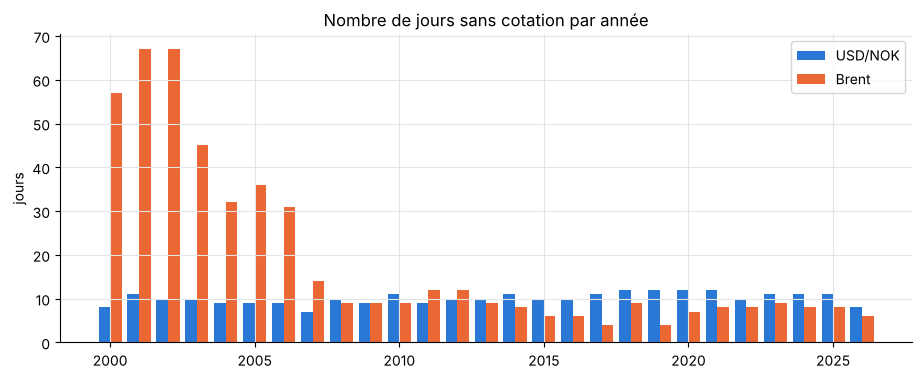

In [4]:
# Où sont les trous ? On compte les valeurs manquantes par année
manquants_nok = usdnok_brut["DEXNOUS"].isna().groupby(usdnok_brut.index.year).sum()
manquants_brent = brent_brut["DCOILBRENTEU"].isna().groupby(brent_brut.index.year).sum()

fig, ax = plt.subplots()
annees = manquants_nok.index
ax.bar(annees - 0.2, manquants_nok, width=0.4, color=BLEU, label="USD/NOK")
ax.bar(annees + 0.2, manquants_brent, width=0.4, color=ORANGE, label="Brent")
ax.set_title("Nombre de jours sans cotation par année")
ax.set_ylabel("jours")
ax.legend()
plt.show()

**Interprétation :**
- **USD/NOK** : environ 10 jours vides par an, ce sont les jours fériés américains (4 juillet, Noël, 1er janvier, Thanksgiving...). Rien d'anormal.
- **Brent** : beaucoup plus de trous entre **2000 et 2006** (jusqu'à 67 jours par an), avec des trous de plusieurs jours d'affilée (jusqu'à 11 jours en février 2002). Ensuite, on revient à une dizaine de jours par an (jours fériés britanniques).
- **Décision :** on **ne remplit pas** les trous (pas d'interpolation), pour ne pas introduire de prix artificiels. On garde uniquement les jours où **les deux** séries sont cotées.

In [5]:
# Valeurs extrêmes : plus bas et plus haut de chaque série
usdnok = usdnok_brut["DEXNOUS"].dropna()       # dropna() retire les cases vides
brent = brent_brut["DCOILBRENTEU"].dropna()

print("USD/NOK : min", usdnok.min(), "le", usdnok.idxmin().date(), "| max", usdnok.max(), "le", usdnok.idxmax().date())
print("Brent   : min", brent.min(), "le", brent.idxmin().date(), "| max", brent.max(), "le", brent.idxmax().date())

USD/NOK : min 4.9467 le 2008-04-16 | max 11.6842 le 2020-03-20
Brent   : min 9.12 le 2020-04-21 | max 143.95 le 2008-07-03


**Interprétation :** les extrêmes correspondent à des événements connus. Le Brent touche 143,95 \$ en juillet 2008 (pic avant la crise financière) et 9,12 \$ le 21 avril 2020 (effondrement de la demande pendant le Covid, saturation des capacités de stockage). Le dollar atteint 11,68 couronnes le 20 mars 2020, au pire de la panique Covid. **Ce sont de vrais prix, on les garde.**

### 1.3 Alignement des dates

Les deux séries n'ont pas le même calendrier : USD/NOK suit les jours ouvrés américains, le Brent les jours ouvrés européens. Avec `join(how="inner")`, on garde uniquement les dates présentes **dans les deux** séries.

In [6]:
donnees = pd.DataFrame({"usdnok": usdnok}).join(pd.DataFrame({"brent": brent}), how="inner")

print("Jours avec USD/NOK seulement :", len(usdnok.index.difference(brent.index)))
print("Jours avec Brent seulement   :", len(brent.index.difference(usdnok.index)))
print("Jours communs gardés         :", len(donnees), "du", donnees.index.min().date(), "au", donnees.index.max().date())

Jours avec USD/NOK seulement : 391
Jours avec Brent seulement   : 161
Jours communs gardés         : 6326 du 2000-01-04 au 2026-10-14


**Point important sur l'heure des prix :** USD/NOK est relevé **à midi à New York**, alors que le Brent spot est un prix européen de fin de journée (le Brent « daté » est évalué vers 16h30 à Londres, soit vers 11h30 à New York). Les deux prix sont donc pris à peu près au même moment, mais pas exactement. On garde ce point en tête pour l'étude des décalages et pour le backtest.

### 1.4 Rendements logarithmiques

On travaille sur les **rendements** et pas sur les prix, car les prix ont une tendance (ils ne sont pas « stationnaires ») et deux séries avec une tendance peuvent sembler corrélées sans aucun lien réel (régression fallacieuse).

Rendement log du jour t : $r_t = \ln(P_t) - \ln(P_{t-1})$. Avantages : il s'additionne dans le temps et il est symétrique (+10 % puis -10 % en log ramène au point de départ).

À cause des trous du Brent, certains rendements couvriraient plusieurs jours (par exemple 11 jours en 2002). On retire les rendements calculés sur **plus de 5 jours calendaires** (un week-end prolongé reste accepté).

In [7]:
donnees["r_nok"] = np.log(donnees["usdnok"]).diff()      # rendement log de USD/NOK
donnees["r_brent"] = np.log(donnees["brent"]).diff()     # rendement log du Brent

# Nombre de jours calendaires entre deux observations
donnees["ecart_jours"] = donnees.index.to_series().diff().dt.days

# Rendement du Brent de la veille (sert pour le décalage et le backtest)
donnees["r_brent_veille"] = donnees["r_brent"].shift(1)

print("Rendements retirés (écart > 5 jours) :", (donnees["ecart_jours"] > 5).sum())
rdt = donnees[donnees["ecart_jours"] <= 5].dropna().copy()
print("Rendements journaliers utilisables   :", len(rdt))

Rendements retirés (écart > 5 jours) : 31
Rendements journaliers utilisables   : 6293


In [8]:
# Statistiques descriptives des rendements journaliers (en %)
stats = pd.DataFrame({
    "moyenne (%)": rdt[["r_nok", "r_brent"]].mean() * 100,
    "écart-type jour (%)": rdt[["r_nok", "r_brent"]].std() * 100,
    "volatilité annuelle (%)": rdt[["r_nok", "r_brent"]].std() * np.sqrt(252) * 100,
    "pire jour (%)": rdt[["r_nok", "r_brent"]].min() * 100,
    "meilleur jour (%)": rdt[["r_nok", "r_brent"]].max() * 100,
})
stats.index = ["USD/NOK", "Brent"]
stats

,moyenne (%),écart-type jour (%),volatilité annuelle (%),pire jour (%),meilleur jour (%)
USD/NOK,0.004,0.786,12.470,-6.444,6.116
Brent,0.026,2.759,43.791,-64.370,41.202


**Interprétation :** le Brent est environ **3 fois plus volatil** que USD/NOK. Le pire jour du Brent (-64 %, le 21 avril 2020) est un point extrême réel. Pour vérifier qu'il ne fausse pas les résultats, on calculera aussi la corrélation de **Spearman**, basée sur les rangs, donc peu sensible aux valeurs extrêmes.

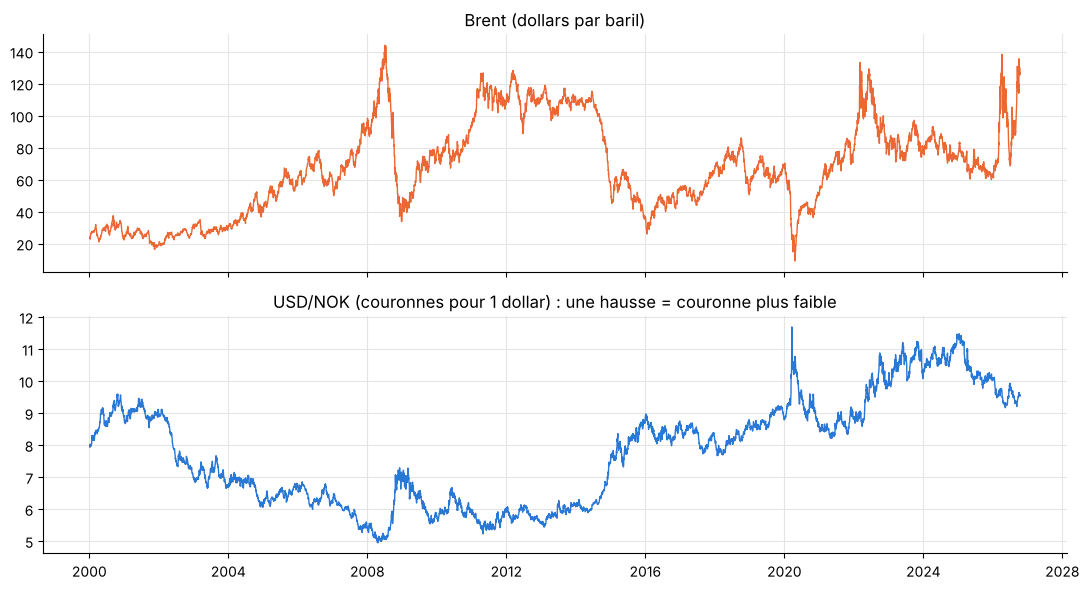

In [9]:
# Prix en niveau : deux graphiques l'un sous l'autre (pas de double axe, qui peut tromper l'œil)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(donnees.index, donnees["brent"], color=ORANGE, linewidth=1)
ax1.set_title("Brent (dollars par baril)")
ax2.plot(donnees.index, donnees["usdnok"], color=BLEU, linewidth=1)
ax2.set_title("USD/NOK (couronnes pour 1 dollar) : une hausse = couronne plus faible")
plt.tight_layout()
plt.show()

**Interprétation :** on voit à l'œil la relation inverse sur les grands mouvements. En 2008, puis en 2014-2015, le Brent s'effondre et USD/NOK grimpe fortement (la couronne perd beaucoup de valeur). En 2020, même chose. En revanche, après 2022, la couronne reste faible même quand le pétrole est cher : la relation semble moins forte récemment. Les sections suivantes le mesurent.

En 2026, le Brent fait un bond de 72 \$ à 138 \$ entre février et avril. L'EIA l'explique par la fermeture du détroit d'Ormuz ([Today in Energy, 24/04/2026](https://www.eia.gov/todayinenergy/detail.php?id=67544)).

### 1.5 Vérification de la stationnarité (test ADF)

Le test de Dickey-Fuller augmenté (ADF) teste l'hypothèse « la série a une racine unitaire », c'est-à-dire qu'elle n'est pas stationnaire. Une p-value **inférieure à 5 %** permet de rejeter cette hypothèse : la série est stationnaire. C'est indispensable pour les tests de Granger et les régressions qui suivent.

In [10]:
tests_adf = pd.DataFrame({
    "p-value ADF": [
        adfuller(np.log(rdt["usdnok"]))[1],
        adfuller(np.log(rdt["brent"]))[1],
        adfuller(rdt["r_nok"])[1],
        adfuller(rdt["r_brent"])[1],
    ]
}, index=["log prix USD/NOK", "log prix Brent", "rendements USD/NOK", "rendements Brent"])
tests_adf

,p-value ADF
log prix USD/NOK,0.652
log prix Brent,0.065
rendements USD/NOK,0.000
rendements Brent,0.000


**Interprétation :** les **prix** ne sont pas stationnaires (p-value au-dessus de 5 % : 0,65 pour USD/NOK, 0,07 pour le Brent, ce qui est limite mais ne permet pas de rejeter la racine unitaire), les **rendements** le sont (p-value proche de 0). On a donc raison de travailler sur les rendements.

## 2. Corrélation

### 2.1 Corrélation globale

On calcule la corrélation entre les rendements de USD/NOK et du Brent sur toute la période, à trois fréquences : journalière, hebdomadaire (prix du vendredi) et mensuelle (prix de fin de mois).

In [11]:
# Journalier : Pearson (classique) et Spearman (sur les rangs, robuste aux extrêmes)
corr_jour = rdt["r_nok"].corr(rdt["r_brent"])
corr_jour_spearman = rdt["r_nok"].corr(rdt["r_brent"], method="spearman")

# Hebdomadaire et mensuel : on prend le dernier prix de chaque semaine / mois, puis le rendement log
prix_semaine = donnees[["usdnok", "brent"]].resample("W-FRI").last()
rdt_semaine = np.log(prix_semaine).diff().dropna()
prix_mois = donnees[["usdnok", "brent"]].resample("ME").last()
rdt_mois = np.log(prix_mois).diff().dropna()

corr_globale = pd.DataFrame({
    "corrélation": [corr_jour, corr_jour_spearman,
                    rdt_semaine["usdnok"].corr(rdt_semaine["brent"]),
                    rdt_mois["usdnok"].corr(rdt_mois["brent"]),
                    rdt.loc[:"2025", "r_nok"].corr(rdt.loc[:"2025", "r_brent"])],
}, index=["journalière (Pearson)", "journalière (Spearman)", "hebdomadaire", "mensuelle",
          "journalière sans 2026"])
corr_globale

,corrélation
journalière (Pearson),-0.268
journalière (Spearman),-0.265
hebdomadaire,-0.333
mensuelle,-0.389
journalière sans 2026,-0.278


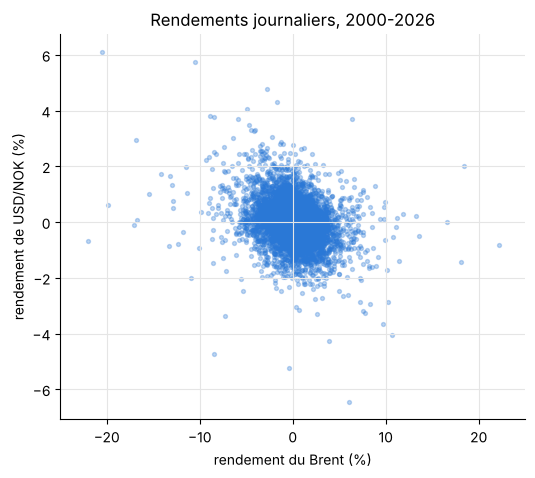

In [12]:
# Nuage de points des rendements journaliers
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(rdt["r_brent"] * 100, rdt["r_nok"] * 100, s=8, alpha=0.3, color=BLEU)
ax.set_xlabel("rendement du Brent (%)")
ax.set_ylabel("rendement de USD/NOK (%)")
ax.set_title("Rendements journaliers, 2000-2026")
ax.set_xlim(-25, 25)   # on coupe l'axe pour la lisibilité : le -64 % du 21/04/2020 sort du cadre
plt.show()

**Interprétation :**
- La corrélation est **négative** à toutes les fréquences : quand le Brent monte, USD/NOK baisse, donc **la couronne s'apprécie**. C'est la signature d'une pétromonnaie.
- Elle est **modérée** : environ -0,27 en journalier. Le pétrole n'explique qu'une petite partie des mouvements quotidiens de la couronne (le R² vaut environ le carré de la corrélation, soit 7 %).
- Elle est **plus forte quand on allonge l'horizon** (-0,33 en hebdomadaire, -0,39 en mensuel). Les variations quotidiennes contiennent beaucoup de « bruit » ; le lien fondamental apparaît mieux sur des horizons plus longs.
- Pearson et Spearman donnent presque le même chiffre : le point extrême d'avril 2020 ne fausse pas le résultat. Retirer 2026 ne change presque rien non plus.

### 2.2 Corrélation glissante (3 mois et 12 mois)

Une seule corrélation sur 26 ans cache peut-être des changements. On calcule donc la corrélation sur une fenêtre qui avance dans le temps : 63 jours de bourse (environ 3 mois) et 252 jours (environ 12 mois).

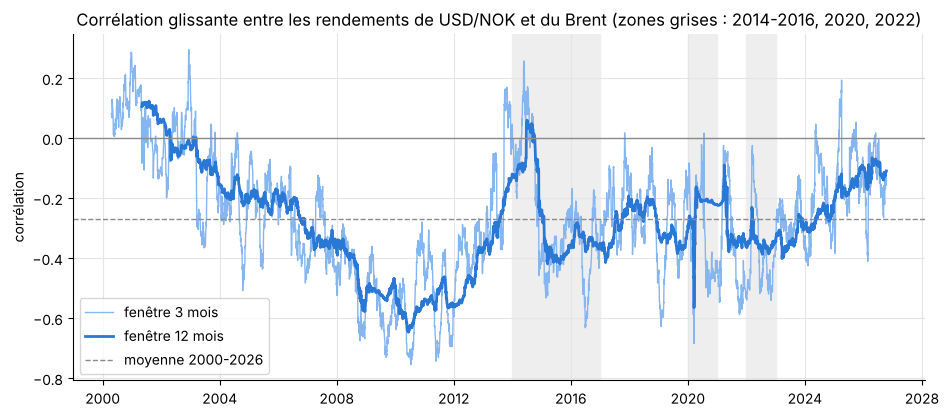

In [13]:
rdt["corr_3m"] = rdt["r_nok"].rolling(63).corr(rdt["r_brent"])
rdt["corr_12m"] = rdt["r_nok"].rolling(252).corr(rdt["r_brent"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rdt.index, rdt["corr_3m"], color="#86b6ef", linewidth=1, label="fenêtre 3 mois")
ax.plot(rdt.index, rdt["corr_12m"], color=BLEU, linewidth=2, label="fenêtre 12 mois")
ax.axhline(0, color=GRIS, linewidth=1)
ax.axhline(corr_jour, color=GRIS, linewidth=1, linestyle="--", label="moyenne 2000-2026")

# Périodes étudiées plus bas, en gris clair
for debut, fin in [("2014-01-01", "2016-12-31"), ("2020-01-01", "2020-12-31"), ("2022-01-01", "2022-12-31")]:
    ax.axvspan(pd.Timestamp(debut), pd.Timestamp(fin), color="#eeeeee", zorder=0)

ax.set_title("Corrélation glissante entre les rendements de USD/NOK et du Brent (zones grises : 2014-2016, 2020, 2022)")
ax.set_ylabel("corrélation")
ax.legend(loc="lower left")
plt.show()

**Interprétation :**
- **2000-2003** : la corrélation sur 12 mois tourne autour de zéro. À cette époque, le lien pétrole/couronne n'est pas visible au jour le jour. Il se renforce ensuite progressivement (environ -0,2 en 2004-2006).
- **2008-2012** : la corrélation devient fortement négative (jusqu'à -0,65 sur 12 mois en 2010). C'est la période où la couronne se comporte le plus comme une pétromonnaie, avec la crise de 2008 où pétrole et couronne chutent ensemble.
- **Depuis 2013** : la corrélation reste négative mais plus faible, en général entre -0,2 et -0,4, avec un creux en 2014 (proche de zéro au moment où la chute du pétrole commence), et elle s'affaiblit encore en 2025-2026 (autour de -0,1 à -0,15).
- La fenêtre de 3 mois est beaucoup plus instable : elle passe au-dessus de zéro environ 9 % du temps. **Sur un trimestre, il arrive que le lien disparaisse.** Un gérant ne peut donc pas compter sur ce lien à court terme.

### 2.3 Corrélation et bêta par période

On découpe l'historique en périodes économiques. Les trois demandées : **2014-2016** (chute du pétrole), **2020** (Covid), **2022** (guerre en Ukraine), plus des périodes de référence pour voir l'évolution.

Pour chaque période, on calcule aussi le **bêta** de la régression $r_{NOK} = \alpha + \beta \cdot r_{Brent}$ : de combien bouge USD/NOK (en %) quand le Brent bouge de 1 %.

In [14]:
periodes = {
    "2000-2007 (avant crise)":       ("2000", "2007"),
    "2008-2009 (crise financière)":  ("2008", "2009"),
    "2010-2013 (pétrole > 100 $)":   ("2010", "2013"),
    "2014-2016 (chute du pétrole)":  ("2014", "2016"),
    "2017-2019":                     ("2017", "2019"),
    "2020 (Covid)":                  ("2020", "2020"),
    "2021":                          ("2021", "2021"),
    "2022 (guerre en Ukraine)":      ("2022", "2022"),
    "2023-2025":                     ("2023", "2025"),
    "2026 (choc d'Ormuz)":           ("2026", "2026"),
}

lignes = []
for nom, (debut, fin) in periodes.items():
    morceau = rdt.loc[debut:fin]
    regression = sm.OLS(morceau["r_nok"], sm.add_constant(morceau["r_brent"])).fit()
    lignes.append({
        "période": nom,
        "jours": len(morceau),
        "corr. Pearson": morceau["r_nok"].corr(morceau["r_brent"]),
        "corr. Spearman": morceau["r_nok"].corr(morceau["r_brent"], method="spearman"),
        "bêta": regression.params["r_brent"],
        "R²": regression.rsquared,
        "vol. Brent annuelle (%)": morceau["r_brent"].std() * np.sqrt(252) * 100,
    })

table_periodes = pd.DataFrame(lignes).set_index("période")
table_periodes

,jours,corr. Pearson,corr. Spearman,bêta,R²,vol. Brent annuelle (%)
période,,,,,,
2000-2007 (avant crise),1658,-0.125,-0.123,-0.035,0.016,39.653
2008-2009 (crise financière),501,-0.519,-0.467,-0.201,0.269,51.156
2010-2013 (pétrole > 100 $),992,-0.439,-0.399,-0.220,0.193,24.799
2014-2016 (chute du pétrole),746,-0.344,-0.308,-0.110,0.118,37.267
2017-2019,738,-0.276,-0.267,-0.073,0.076,30.010
2020 (Covid),246,-0.221,-0.276,-0.034,0.049,116.366
2021,242,-0.357,-0.364,-0.113,0.127,34.347
2022 (guerre en Ukraine),243,-0.332,-0.368,-0.104,0.110,47.651
2023-2025,734,-0.210,-0.170,-0.079,0.044,31.121


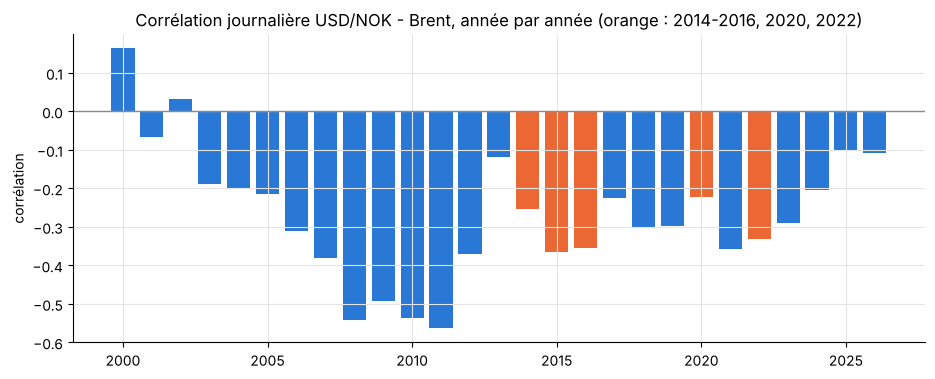

In [15]:
# Corrélation année par année, pour voir l'évolution d'un coup d'œil
corr_par_annee = rdt.groupby(rdt.index.year).apply(lambda x: x["r_nok"].corr(x["r_brent"]))

fig, ax = plt.subplots()
couleurs = [ORANGE if annee in (2014, 2015, 2016, 2020, 2022) else BLEU for annee in corr_par_annee.index]
ax.bar(corr_par_annee.index, corr_par_annee, color=couleurs)
ax.axhline(0, color=GRIS, linewidth=1)
ax.set_title("Corrélation journalière USD/NOK - Brent, année par année (orange : 2014-2016, 2020, 2022)")
ax.set_ylabel("corrélation")
plt.show()

**Interprétation par période :**
- **2014-2016 (chute du pétrole)** : corrélation -0,34 et bêta -0,11. Le Brent passe de 115 \$ (juin 2014) à 26 \$ (janvier 2016), soit -77 %, et USD/NOK grimpe de 5,9 à 9,0 : la couronne perd environ un tiers de sa valeur face au dollar. C'est l'épisode le plus marquant pour la Norvège : le lien est fort et économiquement très important, car les mouvements du pétrole sont énormes.
- **2020 (Covid)** : corrélation Pearson -0,22, plus faible qu'on ne l'attendrait. Pendant la panique de mars 2020, **tout** baisse ensemble (actions, pétrole, devises à risque), et les mouvements extrêmes du Brent (jusqu'à -64 % sur un jour) ne se transmettent pas proportionnellement à la couronne. Le bêta tombe à -0,03 : quand le pétrole bouge de manière extrême, la couronne ne suit pas « à l'échelle ». La corrélation de Spearman (-0,28) est un peu plus forte, ce qui confirme que ce sont les jours extrêmes qui affaiblissent le Pearson.
- **2022 (guerre en Ukraine)** : corrélation -0,33, bêta -0,10, proche de la moyenne historique. Le lien est intact, mais la couronne n'a pas profité autant qu'on l'aurait cru d'un pétrole et d'un gaz très chers (voir section 4 : écart de taux, aversion au risque, dollar fort).
- **Ce qui a changé :** la relation était quasi absente en 2000-2005, très forte entre 2008 et 2013 (bêta autour de -0,2, R² de 20 à 27 %), puis elle s'affaiblit progressivement (bêta autour de -0,08 en 2023-2025 et presque nul en 2026). En 2026, malgré un choc pétrolier énorme, la couronne n'a presque pas suivi le Brent au jour le jour (corrélation -0,11).
- **Un point à retenir :** le **bêta** dépend de la volatilité du Brent. Quand le pétrole devient extrêmement volatil (2020, 2026), le bêta baisse mécaniquement, car la couronne ne suit pas des mouvements de 10 ou 20 % par jour.

## 3. Décalage et causalité

### 3.1 Corrélations croisées

On cherche si le Brent d'un jour est corrélé à la couronne **des jours suivants** (le pétrole « annonce » la couronne), ou l'inverse.

Convention : au décalage $k$, on corrèle $r_{NOK}(t)$ avec $r_{Brent}(t-k)$.
- $k > 0$ : le Brent d'il y a $k$ jours, comparé à la couronne d'aujourd'hui (le Brent mène).
- $k < 0$ : la couronne mène.
- $k = 0$ : même jour.

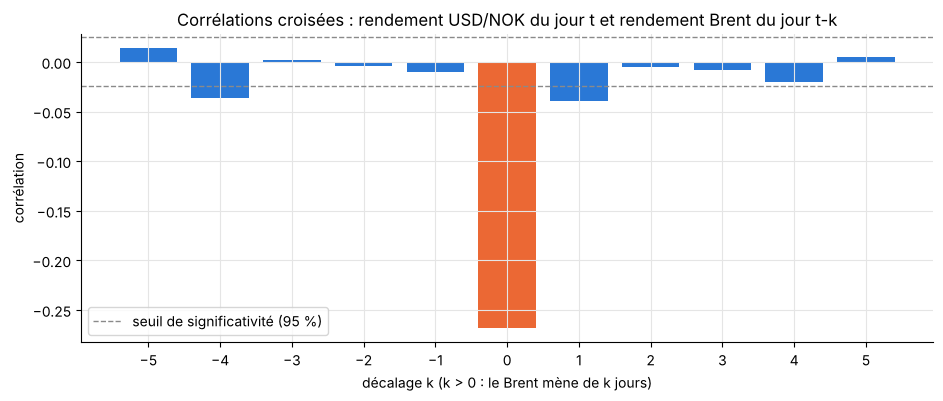

,-5,-4,-3,-2,-1,0,1,2,3,4,5
corrélation,0.014,-0.036,0.002,-0.004,-0.010,-0.268,-0.040,-0.005,-0.008,-0.020,0.005


In [16]:
# On travaille sur les jours alignés (tous les jours communs), puis on retire les écarts > 5 jours
decalages = range(-5, 6)
corr_croisees = []
for k in decalages:
    brent_decale = donnees["r_brent"].shift(k)                       # Brent décalé de k jours
    paire = pd.DataFrame({"nok": donnees["r_nok"], "brent": brent_decale})
    paire = paire[donnees["ecart_jours"] <= 5].dropna()
    corr_croisees.append(paire["nok"].corr(paire["brent"]))

corr_croisees = pd.Series(corr_croisees, index=decalages)

# Seuil de significativité approximatif à 95 % : ±1,96 / racine(nombre d'observations)
seuil = 1.96 / np.sqrt(len(rdt))

fig, ax = plt.subplots()
ax.bar(corr_croisees.index, corr_croisees, color=[ORANGE if k == 0 else BLEU for k in decalages])
ax.axhline(seuil, color=GRIS, linestyle="--", linewidth=1, label="seuil de significativité (95 %)")
ax.axhline(-seuil, color=GRIS, linestyle="--", linewidth=1)
ax.set_xticks(list(decalages))
ax.set_xlabel("décalage k (k > 0 : le Brent mène de k jours)")
ax.set_ylabel("corrélation")
ax.set_title("Corrélations croisées : rendement USD/NOK du jour t et rendement Brent du jour t-k")
ax.legend()
plt.show()

corr_croisees.to_frame("corrélation").T

**Interprétation :**
- Presque toute la relation est **le même jour** (décalage 0 : -0,27). Le marché des changes intègre l'information pétrolière très vite.
- Au décalage **+1** (Brent de la veille), on trouve une petite corrélation de -0,04, juste au-dessus du seuil de significativité. Ce petit effet peut avoir deux origines : un léger retard de réaction de la couronne, ou un **effet d'horloge** (les deux prix ne sont pas relevés exactement à la même heure, voir section 1.3).
- Au décalage **-4** (la couronne d'il y a 4 jours), la corrélation (-0,036) dépasse aussi légèrement le seuil. Mais quand on teste 11 décalages au seuil de 5 %, on s'attend à environ un dépassement dû au hasard, et aucune raison économique ne justifie qu'une petite devise annonce le pétrole 4 jours à l'avance : on ne le retient pas.
- Aux autres décalages, les corrélations sont proches de zéro : **pas de mémoire longue**. Cela correspond à un marché des changes globalement efficient.

### 3.2 Test de causalité de Granger

« Le Brent cause la NOK au sens de Granger » signifie : les rendements passés du Brent améliorent la prévision des rendements de la NOK, **en plus** des rendements passés de la NOK elle-même. C'est une notion de **prévisibilité**, pas de causalité économique au sens strict.

- Hypothèse nulle : le Brent passé n'apporte aucune information.
- p-value < 5 % : on rejette l'hypothèse nulle, le Brent aide à prévoir la NOK.

On teste les deux sens, avec 1 à 5 jours de retard. On le fait sur toute la période, puis séparément sur 2000-2015 et 2016-2026 (ce découpage servira aussi au backtest).

In [17]:
def p_values_granger(tableau, retard_max=5):
    # grangercausalitytests teste si la 2e colonne aide à prévoir la 1re colonne.
    # On garde la p-value du test F pour chaque nombre de retards.
    resultats = grangercausalitytests(tableau, maxlag=retard_max)
    return [resultats[retard][0]["ssr_ftest"][1] for retard in range(1, retard_max + 1)]

lignes = {}
for nom, (debut, fin) in {"2000-2026": ("2000", "2026"), "2000-2015": ("2000", "2015"), "2016-2026": ("2016", "2026")}.items():
    morceau = rdt.loc[debut:fin]
    lignes["Brent → NOK, " + nom] = p_values_granger(morceau[["r_nok", "r_brent"]])
    lignes["NOK → Brent, " + nom] = p_values_granger(morceau[["r_brent", "r_nok"]])

table_granger = pd.DataFrame(lignes, index=["1 jour", "2 jours", "3 jours", "4 jours", "5 jours"]).T
table_granger.style.format("{:.4f}").map(lambda v: "background-color: #cde2fb" if v < 0.05 else "")

,1 jour,2 jours,3 jours,4 jours,5 jours
"Brent → NOK, 2000-2026",0.0011,0.0026,0.0065,0.0023,0.0044
"NOK → Brent, 2000-2026",0.2433,0.3033,0.4902,0.0262,0.0408
"Brent → NOK, 2000-2015",0.4148,0.5775,0.7928,0.4690,0.5815
"NOK → Brent, 2000-2015",0.9064,0.6371,0.6109,0.2405,0.3216
"Brent → NOK, 2016-2026",0.0002,0.0005,0.0011,0.0011,0.0020
"NOK → Brent, 2016-2026",0.2389,0.3749,0.3847,0.0563,0.0743


**Interprétation (cases en bleu : p-value < 5 %) :**
- **Brent → NOK** : sur l'ensemble 2000-2026, les p-values sont très faibles (environ 0,001 à 0,006). Le Brent des jours précédents aide un peu à prévoir la couronne. Mais ce résultat vient **entièrement de la période 2016-2026** (p-values de 0,0002 à 0,002) : sur 2000-2015, le test n'est **pas significatif du tout** (p-values de 0,41 à 0,79). L'effet est donc apparu récemment, et rien ne garantit qu'il durera.
- **NOK → Brent** : pas de prévisibilité à 1, 2 ou 3 jours (p-values entre 0,24 et 0,49). À 4 et 5 jours sur l'ensemble de la période, les p-values passent juste sous 5 % (0,03 et 0,04), mais elles ne le sont plus sur chacune des deux sous-périodes : c'est un résultat fragile, qu'on ne retient pas. C'est logique : la Norvège est un petit acteur, sa monnaie ne fait pas le prix mondial du pétrole. La Norges Bank fait d'ailleurs la même hypothèse dans ses modèles (le pétrole est « exogène » pour la Norvège).
- **Remarque :** « statistiquement significatif » ne veut pas dire « économiquement important ». Avec plus de 6 000 observations, un effet minuscule (corrélation de -0,04) devient significatif. La vraie question est de savoir s'il est **exploitable** après coûts : c'est l'objet du backtest (section 6).

### 3.3 Régression des rendements de la NOK sur ceux du Brent

Modèle : $r_{NOK,t} = \alpha + \beta_0 \cdot r_{Brent,t} + \beta_1 \cdot r_{Brent,t-1} + \varepsilon_t$

- $\beta_0$ : effet du jour même.
- $\beta_1$ : effet du Brent de la veille.

On utilise des **erreurs-types robustes (HAC, Newey-West)**, qui corrigent l'hétéroscédasticité (volatilité qui change dans le temps) et l'autocorrélation des résidus. Sans cette correction, les t-stats seraient trop optimistes.

In [18]:
X = sm.add_constant(rdt[["r_brent", "r_brent_veille"]])
regression = sm.OLS(rdt["r_nok"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(regression.summary().tables[1])
print("\nR² :", round(regression.rsquared, 3), "| nombre d'observations :", int(regression.nobs))

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const           6.771e-05   9.17e-05      0.738      0.460      -0.000       0.000
r_brent           -0.0765      0.010     -7.669      0.000      -0.096      -0.057
r_brent_veille    -0.0117      0.006     -1.822      0.068      -0.024       0.001

R² : 0.074 | nombre d'observations : 6293


**Interprétation :**
- $\beta_0 \approx -0{,}076$ : quand le Brent monte de **10 %** un jour donné, USD/NOK baisse en moyenne d'environ **0,76 %** le même jour (la couronne s'apprécie). Le coefficient est très significatif.
- $\beta_1 \approx -0{,}012$ (Brent de la veille) est environ 6 fois plus petit que l'effet du jour même, et il **n'est pas significatif à 5 %** (p ≈ 0,07) une fois les erreurs-types robustes utilisées. Le test de Granger, qui ne corrige pas la volatilité variable, est donc plus optimiste. L'essentiel de l'effet passe le jour même.
- **R² d'environ 7-8 %** : le pétrole explique une petite part des variations quotidiennes de la couronne. Les autres facteurs (écart de taux d'intérêt, appétit pour le risque, force du dollar, liquidité de la NOK) pèsent davantage au jour le jour.

### 3.4 Stabilité du bêta dans le temps

On ré-estime le bêta du jour même sur une fenêtre glissante de 252 jours (12 mois). Formule simple : $\beta = \text{Cov}(r_{NOK}, r_{Brent}) / \text{Var}(r_{Brent})$.

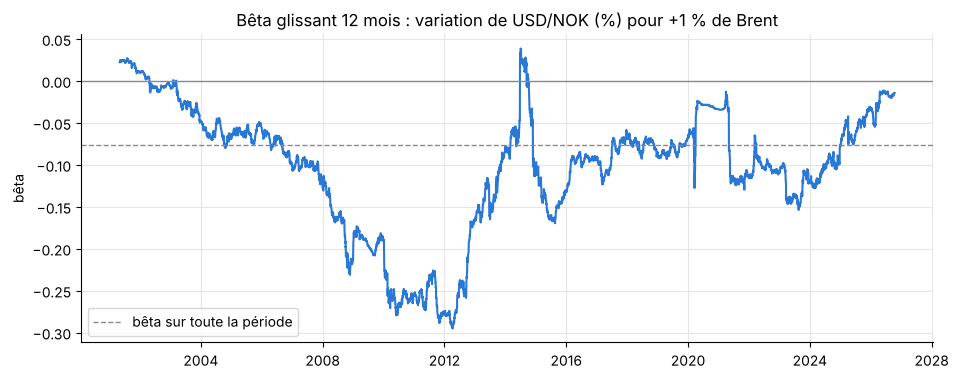

In [19]:
covariance = rdt["r_nok"].rolling(252).cov(rdt["r_brent"])
variance = rdt["r_brent"].rolling(252).var()
rdt["beta_12m"] = covariance / variance

fig, ax = plt.subplots()
ax.plot(rdt.index, rdt["beta_12m"], color=BLEU, linewidth=1.5)
ax.axhline(0, color=GRIS, linewidth=1)
ax.axhline(regression.params["r_brent"], color=GRIS, linewidth=1, linestyle="--", label="bêta sur toute la période")
ax.set_title("Bêta glissant 12 mois : variation de USD/NOK (%) pour +1 % de Brent")
ax.set_ylabel("bêta")
ax.legend(loc="lower left")
plt.show()

**Interprétation :** le bêta **n'est pas stable**. Il est proche de zéro au début des années 2000, atteint environ -0,25 à -0,3 entre 2010 et 2012, puis tourne autour de -0,1 de 2015 à 2024, avant de remonter vers zéro avec les chocs pétroliers extrêmes (2020, et surtout 2026 où il finit vers -0,01). Conséquence pratique : un gérant qui couvre une exposition en couronnes avec du pétrole (ou l'inverse) doit **ré-estimer régulièrement** son ratio de couverture.

## 4. Comparaison avec les publications de la Norges Bank

### 4.1 Documents utilisés

1. **ter Ellen, S. (2016)**, *Nonlinearities in the relationship between oil price changes and movements in the Norwegian krone*, Norges Bank Staff Memo 18/2016. [Lien (PDF)](https://www.norges-bank.no/contentassets/0e24aab656ef4e3e987eb0044b324565/staff-memo-18_2016_eng.pdf)
   Données mensuelles 2001-2015. Élasticité moyenne d'environ **-0,066** : +10 % de pétrole ≈ +0,6 à 0,7 % d'appréciation de la couronne. Effet plus fort pour les **grosses variations** et quand le pétrole passe **sous environ 75 \$**. Pas d'asymétrie significative hausse / baisse. Relation « not stable over time ».
2. **ter Ellen, S. et Martinsen, K. (2016)**, *Oil price shocks and the Norwegian effective exchange rate – an SVAR approach*, Norges Bank Staff Memo 16/2016. [Lien (PDF)](https://www.norges-bank.no/contentassets/d0d21c7e8c8c4ae5b619569a435a8c63/staff-memo-16_2016.pdf)
   Données hebdomadaires 1999-2015, modèle VAR structurel. +10 % de pétrole → couronne +0,5 % à l'impact. Sensibilité **croissante** dans le temps : environ 0,16 % en 1999-2002, 0,33 % en 2003-2006, 1,1 % en 2013-2015. Hypothèse : les variables norvégiennes n'influencent pas le prix du pétrole.
3. **Martinsen, K. (2017)**, *Norges Bank's BEER models for the Norwegian effective exchange rate*, Norges Bank Staff Memo 7/2017. [Lien (PDF)](https://www.norges-bank.no/contentassets/d98b46b49ba44702b30773772c040f08/staff_memo_7_2017.pdf)
   Modèles de taux de change d'équilibre : coefficient du pétrole (en niveau) entre **-0,09 et -0,12**. Le pétrole est l'un des trois fondamentaux de la couronne, avec les prix relatifs et la balance des paiements.
4. **Norges Bank, Monetary Policy Report 1/2023**, encadré *The krone exchange rate in Norges Bank's models*. [Lien](https://www.norges-bank.no/en/news-events/publications/Monetary-Policy-Report/2023/mpr-12023/web-report-mpr-12023/)
   « Historically, there has been a close relationship between movements in the krone exchange rate and oil prices. » La faiblesse de la couronne en 2022-2023 est attribuée à la baisse du pétrole depuis mi-2022, à un **écart de taux** devenu faible face aux partenaires commerciaux, et à une **prime de risque** plus élevée.
5. **Norges Bank, Monetary Policy Report 4/2025**. [Lien](https://www.norges-bank.no/en/news-events/publications/Monetary-Policy-Report/2025/mpr-42025/web-report-mpr-42025/)
   La dépréciation récente « coincides with lower oil prices » et avec un écart de taux plus faible.

**Différence de méthode à garder en tête :** la Norges Bank étudie surtout l'**I44**, un indice de la couronne contre un panier de 44 devises (pondéré par le commerce). Nous étudions **USD/NOK**, contre le seul dollar. Or le Brent est coté en dollars, et le dollar a tendance à monter quand le pétrole baisse : USD/NOK contient donc un « effet dollar » en plus de l'effet pétrole. **On s'attend à des coefficients plus élevés (en valeur absolue) que ceux de la Norges Bank.** Dans les deux cas, une hausse de l'indice correspond à une couronne plus faible, donc les signes sont comparables.

### 4.2 Réplication simplifiée sur nos données

Pour rendre les résultats comparables, on reprend les choix de la Norges Bank :
- comme ter Ellen (2016) : rendements **mensuels**, de janvier 2001 à août 2015 ;
- comme ter Ellen et Martinsen (2016) : rendements **hebdomadaires**, sur des sous-périodes proches des leurs.

In [20]:
# 1) Mensuel, même période que ter Ellen (2016)
mois = rdt_mois.loc["2001-01":"2015-08"]
reg_mois = sm.OLS(mois["usdnok"], sm.add_constant(mois["brent"])).fit()
print("Mensuel 2001-01 à 2015-08 : bêta =", round(reg_mois.params["brent"], 3), "| R² =", round(reg_mois.rsquared, 3))
print("ter Ellen (2016) sur l'I44 : élasticité ≈ -0,066\n")

# 2) Hebdomadaire, sous-périodes proches de ter Ellen et Martinsen (2016)
sous_periodes = {"2000-2002": ("2000", "2002"), "2003-2006": ("2003", "2006"), "2007-2010": ("2007", "2010"),
                 "2013-2015": ("2013", "2015"), "2016-2019": ("2016", "2019"), "2020-2026": ("2020", "2026")}
lignes = []
for nom, (debut, fin) in sous_periodes.items():
    semaines = rdt_semaine.loc[debut:fin]
    reg = sm.OLS(semaines["usdnok"], sm.add_constant(semaines["brent"])).fit()
    lignes.append({"période": nom, "bêta hebdo": reg.params["brent"], "effet de +10 % de Brent (%)": reg.params["brent"] * 10, "R²": reg.rsquared})

table_hebdo = pd.DataFrame(lignes).set_index("période")
table_hebdo["Norges Bank, SVAR sur l'I44 (impact de +10 %)"] = ["≈ -0,16 % (1999-2002)", "≈ -0,33 %", "n.d.", "≈ -1,1 %", "hors échantillon", "hors échantillon"]
table_hebdo

Mensuel 2001-01 à 2015-08 : bêta = -0.159 | R² = 0.233
ter Ellen (2016) sur l'I44 : élasticité ≈ -0,066



,bêta hebdo,effet de +10 % de Brent (%),R²,"Norges Bank, SVAR sur l'I44 (impact de +10 %)"
période,,,,
2000-2002,-0.001,-0.006,0.000,"≈ -0,16 % (1999-2002)"
2003-2006,-0.090,-0.903,0.074,"≈ -0,33 %"
2007-2010,-0.211,-2.115,0.373,n.d.
2013-2015,-0.135,-1.349,0.114,"≈ -1,1 %"
2016-2019,-0.075,-0.753,0.071,hors échantillon
2020-2026,-0.092,-0.919,0.104,hors échantillon


### 4.3 Ce qui concorde et ce qui diffère

**Ce qui concorde :**
- **Le signe et le mécanisme** : pétrole en hausse → couronne plus forte, dans tous nos calculs comme dans toutes les publications de la Norges Bank.
- **Une relation instable dans le temps** : ter Ellen (2016) écrit que la relation « is not stable over time » ; nos corrélations et bêtas glissants le montrent clairement.
- **Une sensibilité qui augmente du début des années 2000 à 2015** : notre bêta hebdomadaire passe de 0 en 2000-2002 à environ -0,09 en 2003-2006, puis -0,2 en 2007-2010 et -0,14 en 2013-2015. La Norges Bank trouve la même progression (0,16 % → 0,33 % → 1,1 % pour +10 % de pétrole).
- **Le rôle des gros mouvements** : ter Ellen trouve que les grosses variations du pétrole ont plus d'effet. Nos résultats sur 2014-2016 vont dans ce sens (forte dépréciation de la couronne pendant la grande chute du pétrole).
- **Le pétrole n'est pas seul** : la Norges Bank (MPR 1/2023, 4/2025) cite aussi l'écart de taux et la prime de risque. Nos R² faibles (7 % en journalier, 23 % en mensuel) le confirment : le pétrole n'explique qu'une partie de la couronne.
- **Le sens de la causalité** : la Norges Bank suppose que la Norvège n'influence pas le pétrole ; notre test de Granger NOK → Brent ne montre pas de prévisibilité à 1-3 jours.

**Ce qui diffère :**
- **L'ampleur** : notre bêta mensuel (environ -0,16 sur 2001-2015) est **plus de deux fois** celui de ter Ellen (-0,066). Explication principale : nous mesurons USD/NOK, qui contient l'effet dollar, alors que l'I44 est un panier. Une partie de notre « effet pétrole » est en fait un « effet dollar ».
- **Après 2015, la relation s'affaiblit dans nos données** (bêta hebdomadaire autour de -0,08 à -0,09 après 2016), alors que les mémos de 2016 décrivaient une sensibilité **croissante**. Les publications récentes (MPR 2023 et 2025) mettent d'ailleurs davantage l'accent sur l'écart de taux et la prime de risque pour expliquer la faiblesse de la couronne. Nos chiffres sont cohérents avec ce changement de discours, mais **nous n'avons pas de publication de la Norges Bank qui mesure directement l'affaiblissement de l'élasticité après 2016** : c'est notre propre constat.
- **Méthode** : la Norges Bank utilise des modèles plus riches (VAR structurels, contrôle des taux d'intérêt, effets de seuil). Nos régressions simples ne contrôlent pas l'écart de taux, ce qui peut biaiser le bêta.

## 5. Fondamentaux du pétrole : contango et backwardation

**Limite :** l'analyse ne dispose pas de données de futures (courbe CO1 à CO12). Cette section est donc **qualitative** et s'appuie sur des publications de l'EIA. Le seul lien chiffré possible est de mettre en regard la structure de la courbe **décrite par l'EIA** pour certains épisodes et la corrélation NOK/Brent **mesurée dans nos données** sur ces mêmes épisodes.

### 5.1 Les deux formes de la courbe

La courbe des futures donne le prix du pétrole pour une livraison dans 1 mois, 2 mois... 12 mois.

- **Contango** : les échéances lointaines sont **plus chères** que l'échéance proche. Le marché est **bien approvisionné**, les stocks sont élevés. Acheter du pétrole aujourd'hui, le stocker et le revendre à terme devient rentable, tant que l'écart couvre les coûts de stockage et de financement. L'EIA note qu'en janvier 2016, le Brent à 1 mois cotait en moyenne environ **8 \$ de moins** que l'échéance à un an, et que le stockage sur pétrolier (« floating storage ») ne devient rentable qu'à partir d'un contango de **10 à 12 \$/baril** ([EIA, Today in Energy, 04/02/2016](https://www.eia.gov/todayinenergy/detail.php?id=24832)).
- **Backwardation** : l'échéance proche est **plus chère** que les échéances lointaines. Le marché est **tendu**, les stocks sont bas, et un baril disponible tout de suite vaut plus qu'un baril livré plus tard (« rendement d'opportunité » ou *convenience yield*). L'EIA explique qu'en novembre 2021, des stocks bas (stocks pétroliers de l'OCDE en baisse de 424 millions de barils) poussaient les contrats proches au-dessus des contrats lointains ([EIA, Today in Energy, 18/11/2021](https://www.eia.gov/todayinenergy/detail.php?id=50396)).

**Le lien avec les stocks :** l'EIA décrit les stocks comme le « point d'équilibre » entre l'offre et la demande, et note que plus l'écart entre le futures à 12 mois et le futures à 1 mois est positif (contango), plus l'incitation à constituer des stocks est forte ([EIA, What drives crude oil prices: Balance](https://www.eia.gov/finance/markets/crudeoil/balance.php)).

**Le lien avec l'OPEP+ :** l'OPEP+ agit sur l'offre, donc sur les stocks, donc sur la forme de la courbe.
- Des **réductions de production** vident les stocks et poussent vers la backwardation. Exemple : l'accord d'avril 2020 prévoyait une baisse initiale de **9,7 millions de barils par jour**, ce qui a entraîné d'importantes baisses de stocks dès juin 2020 ([EIA, Today in Energy, 23/09/2020](https://www.eia.gov/todayinenergy/detail.php?id=45236)).
- Des **hausses de production** remplissent les stocks et poussent vers le contango. En 2025, les hausses d'objectifs de production de l'OPEP+ et une offre supérieure à la demande ont entraîné des hausses de stocks de **plus de 2,5 millions de barils par jour** au second semestre, et le Brent est passé de 79 \$ en moyenne en janvier à 63 \$ en décembre ([EIA, Today in Energy, 05/01/2026](https://www.eia.gov/todayinenergy/detail.php?id=66944)).

### 5.2 Mise en regard avec la relation NOK / Brent

Pour chaque épisode, la forme de la courbe vient des sources (colonne « source ») ; la corrélation vient de nos données.

In [21]:
episodes = [
    # (épisode, début, fin, structure de la courbe d'après la source, source)
    ("2010-2013 : pétrole cher, marché tendu", "2010", "2013",
     "backwardation (le Brent proche cote au-dessus de l'échéance à un an de 2010 à 2014)", "EIA 04/02/2016"),
    ("2015 : surabondance, stocks élevés", "2015", "2015",
     "contango (fin de la backwardation de 2010-2014) ; ≈ 8 $ sur un an en janvier 2016", "EIA 04/02/2016"),
    ("mars-mai 2020 : effondrement Covid", "2020-03", "2020-05",
     "stockages saturés, contrats proches très en dessous des lointains (contango extrême)", "EIA 27/04/2020"),
    ("2021-2022 : stocks bas, puis guerre", "2021-07", "2022-12",
     "backwardation liée à des stocks bas", "EIA 18/11/2021"),
    ("2025 : surplus OPEP+, stocks en hausse", "2025", "2025",
     "pas de courbe décrite ; des stocks en hausse poussent en principe vers le contango", "EIA 05/01/2026 (déduction)"),
    ("mars-avril 2026 : fermeture d'Ormuz", "2026-03", "2026-04",
     "backwardation extrême : spot Brent > 25 $ au-dessus du futures proche", "EIA 24/04/2026"),
]

lignes = []
for nom, debut, fin, structure, source in episodes:
    morceau = rdt.loc[debut:fin]
    lignes.append({
        "épisode": nom,
        "structure de la courbe (source)": structure,
        "source": source,
        "Brent sur l'épisode (%)": (np.exp(morceau["r_brent"].sum()) - 1) * 100,
        "USD/NOK sur l'épisode (%)": (np.exp(morceau["r_nok"].sum()) - 1) * 100,
        "corrélation journalière": morceau["r_nok"].corr(morceau["r_brent"]),
    })

table_episodes = pd.DataFrame(lignes).set_index("épisode")
table_episodes

,structure de la courbe (source),source,Brent sur l'épisode (%),USD/NOK sur l'épisode (%),corrélation journalière
épisode,,,,,
"2010-2013 : pétrole cher, marché tendu",backwardation (le Brent proche cote au-dessus ...,EIA 04/02/2016,41.124,4.763,-0.439
"2015 : surabondance, stocks élevés",contango (fin de la backwardation de 2010-2014...,EIA 04/02/2016,-33.762,18.346,-0.364
mars-mai 2020 : effondrement Covid,"stockages saturés, contrats proches très en de...",EIA 27/04/2020,-33.444,2.979,-0.183
"2021-2022 : stocks bas, puis guerre",backwardation liée à des stocks bas,EIA 18/11/2021,4.398,14.713,-0.377
"2025 : surplus OPEP+, stocks en hausse",pas de courbe décrite ; des stocks en hausse p...,EIA 05/01/2026 (déduction),-17.739,-11.318,-0.101
mars-avril 2026 : fermeture d'Ormuz,backwardation extrême : spot Brent > 25 $ au-d...,EIA 24/04/2026,74.201,-2.289,0.013


**Interprétation :**

1. **Pourquoi la forme de la courbe compte pour la couronne.** La couronne réagit surtout à ce que le pétrole rapportera à la Norvège **dans la durée** (recettes de l'État, investissements pétroliers, emploi). Or le prix spot et les échéances proches reflètent souvent une tension **temporaire**. En backwardation, une hausse du spot n'est pas forcément suivie par les échéances lointaines : le marché « pense » que la hausse ne durera pas. Les compagnies pétrolières et l'État norvégien raisonnent sur des prix moyens de long terme. **La couronne a donc moins de raisons de suivre un choc de spot qui n'est pas confirmé par le bas de la courbe.**
2. **C'est cohérent avec nos chiffres.** Pendant les deux chocs les plus extrêmes, la couronne suit peu le Brent : en mars-mai 2020 (contango extrême), le Brent perd 33 % mais USD/NOK ne monte que de 3 % (corrélation -0,18) ; en mars-avril 2026 (backwardation extrême), le Brent gagne 74 % et USD/NOK ne baisse que de 2 %, avec une corrélation journalière nulle (+0,01). Ces mouvements de spot reflètent des problèmes de stockage ou de logistique plutôt qu'un changement durable de la richesse pétrolière norvégienne.
3. **À l'inverse,** en 2015, la baisse touchait **toute la courbe** (surplus durable, stocks élevés, contango) : c'était un vrai changement des revenus futurs de la Norvège. Le Brent perd 34 %, USD/NOK monte de 18 %, et la corrélation est forte (-0,36). En 2010-2013, période de backwardation « normale » et durable, la corrélation est la plus forte de l'échantillon (-0,44).
4. **Le dollar brouille la lecture.** En 2021-2022, le Brent ne monte que de 4 % sur l'épisode mais USD/NOK grimpe de 15 % (dollar très fort en 2022). En 2025, le Brent baisse de 18 % mais USD/NOK baisse de 11 % (dollar faible). Sur ces épisodes, le niveau de USD/NOK suit le dollar plus que le pétrole, même si la corrélation journalière reste négative.
5. **Une hypothèse à tester** (avec des données CO1-CO12) : la couronne serait plus corrélée aux échéances **lointaines** (CO12) qu'au spot. On pourrait calculer la corrélation de USD/NOK avec CO1 et avec CO12, et avec l'écart CO1 - CO12 comme mesure de la tension du marché. **Cette hypothèse n'est pas vérifiée ici**, faute de données.

**Limite :** ces observations portent sur quelques épisodes seulement, et la structure de la courbe vient de descriptions de l'EIA, pas d'une série chiffrée. C'est une piste d'interprétation, pas une preuve.

## 6. Backtest d'une stratégie simple

### 6.1 Règle de la stratégie

Idée : utiliser le petit effet du Brent de la veille trouvé en section 3.
- Si le Brent a **monté** hier, on s'attend à une couronne plus forte aujourd'hui → **vendre USD/NOK** (position = -1).
- Si le Brent a **baissé** hier → **acheter USD/NOK** (position = +1).

Formule : position(t) = -signe(rendement du Brent en t-1). Gain du jour = position × rendement de USD/NOK du jour t.

**Calendrier (horloge) :** le Brent de la veille est connu vers 11h30 (heure de New York) la veille ; on prend la position au fixing de midi de la veille et on la garde jusqu'au fixing de midi du jour. En pratique, c'est très serré (30 minutes) et l'heure exacte du prix EIA n'est pas documentée : c'est une **hypothèse optimiste**.

### 6.2 Échantillon et hors échantillon

- **Échantillon d'apprentissage : 2000-2015.** On y vérifie dans quel sens jouer : si la corrélation entre le Brent de la veille et la NOK est négative, on garde la règle ci-dessus, sinon on l'inverse.
- **Test hors échantillon : 2016-2026.** On applique la règle sans plus rien changer. C'est la seule performance qui compte.

### 6.3 Coûts de transaction

À chaque changement de position, on paie un coût par unité échangée. Passer de +1 à -1 représente 2 unités, donc 2 fois le coût. On teste plusieurs niveaux de coût : 0, 0,5, 1, 2 et 3 points de base (1 pb = 0,01 %) par unité. Ce niveau de coût est une hypothèse, d'où l'analyse de sensibilité.

In [22]:
# Étape 1 : vérifier le sens de la règle sur 2000-2015
apprentissage = rdt.loc["2000":"2015"]
corr_veille = apprentissage["r_nok"].corr(apprentissage["r_brent_veille"])
sens = -1 if corr_veille < 0 else 1
print("Corrélation NOK(t) / Brent(t-1) sur 2000-2015 :", round(corr_veille, 4), "→ position = ", sens, "x signe(Brent de la veille)")

# Étape 2 : construire les positions et les gains bruts sur toute la période
rdt["position"] = sens * np.sign(rdt["r_brent_veille"])
rdt["gain_brut"] = rdt["position"] * rdt["r_nok"]
rdt["unites_echangees"] = rdt["position"].diff().abs().fillna(1)   # 0 si on garde la position, 2 si on la retourne

Corrélation NOK(t) / Brent(t-1) sur 2000-2015 : -0.0088 → position =  -1 x signe(Brent de la veille)


In [23]:
def indicateurs(gains):
    # Mesures de performance d'une série de gains journaliers (en rendement log)
    rendement_annuel = gains.mean() * 252
    volatilite_annuelle = gains.std() * np.sqrt(252)
    richesse = np.exp(gains.cumsum())                   # valeur de 1 € investi
    drawdown_max = (richesse / richesse.cummax() - 1).min()
    return {
        "rendement annuel (%)": rendement_annuel * 100,
        "volatilité annuelle (%)": volatilite_annuelle * 100,
        "Sharpe": rendement_annuel / volatilite_annuelle,     # sans taux sans risque, voir remarque
        "drawdown max (%)": drawdown_max * 100,
        "% de jours gagnants": (gains > 0).mean() * 100,
    }

test = rdt.loc["2016":"2026"]

lignes = {"Apprentissage 2000-2015, sans coût": indicateurs(rdt.loc["2000":"2015", "gain_brut"])}
for cout_pb in [0, 0.5, 1, 2, 3]:
    gains_nets = test["gain_brut"] - cout_pb / 10000 * test["unites_echangees"]
    lignes[f"Hors échantillon 2016-2026, coût {cout_pb} pb"] = indicateurs(gains_nets)

table_backtest = pd.DataFrame(lignes).T
print("Retournements de position par an (hors échantillon) :", round((test["unites_echangees"] > 0).sum() / (len(test) / 252)))
table_backtest

Retournements de position par an (hors échantillon) : 127


,rendement annuel (%),volatilité annuelle (%),Sharpe,drawdown max (%),% de jours gagnants
"Apprentissage 2000-2015, sans coût",1.685,12.992,0.130,-44.815,49.918
"Hors échantillon 2016-2026, coût 0 pb",7.489,11.555,0.648,-19.650,49.792
"Hors échantillon 2016-2026, coût 0.5 pb",6.245,11.554,0.541,-22.297,49.490
"Hors échantillon 2016-2026, coût 1 pb",5.002,11.554,0.433,-24.857,49.263
"Hors échantillon 2016-2026, coût 2 pb",2.515,11.556,0.218,-29.727,48.696
"Hors échantillon 2016-2026, coût 3 pb",0.029,11.560,0.002,-34.281,47.788


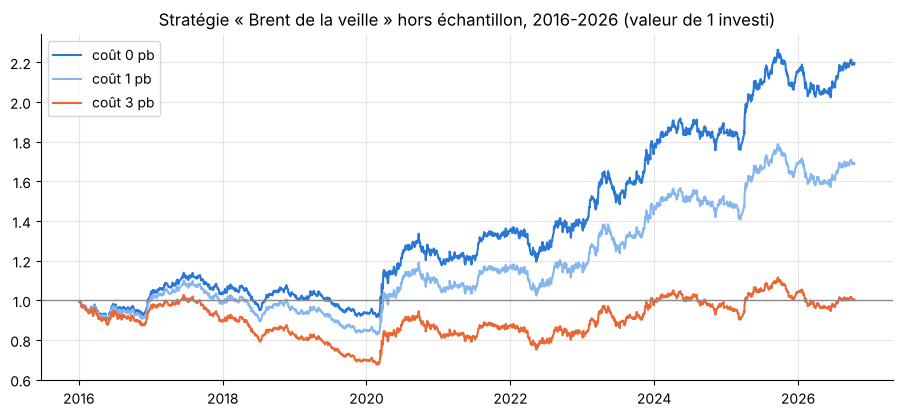

In [24]:
# Performance cumulée hors échantillon (valeur de 1 investi), pour 0, 1 et 3 pb de coût
fig, ax = plt.subplots(figsize=(11, 4.5))
for cout_pb, couleur in [(0, BLEU), (1, "#86b6ef"), (3, ORANGE)]:
    gains_nets = test["gain_brut"] - cout_pb / 10000 * test["unites_echangees"]
    ax.plot(test.index, np.exp(gains_nets.cumsum()), color=couleur, linewidth=1.5, label=f"coût {cout_pb} pb")
ax.axhline(1, color=GRIS, linewidth=1)
ax.set_title("Stratégie « Brent de la veille » hors échantillon, 2016-2026 (valeur de 1 investi)")
ax.legend(loc="upper left")
plt.show()

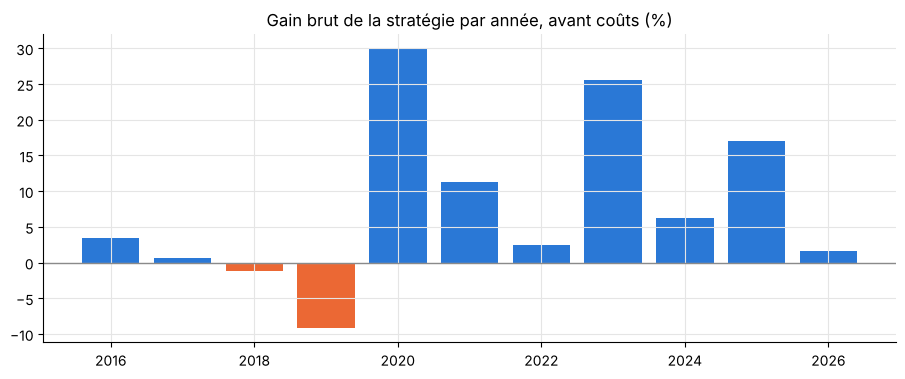

Coût de point mort : 3.0 pb par unité échangée


In [25]:
# Gain brut par année hors échantillon (en %) : la performance est-elle régulière ?
gain_par_annee = (np.exp(test["gain_brut"].groupby(test.index.year).sum()) - 1) * 100
fig, ax = plt.subplots()
ax.bar(gain_par_annee.index, gain_par_annee, color=[BLEU if g >= 0 else ORANGE for g in gain_par_annee])
ax.axhline(0, color=GRIS, linewidth=1)
ax.set_title("Gain brut de la stratégie par année, avant coûts (%)")
plt.show()

# Coût qui ramène le gain à zéro (en pb par unité échangée)
cout_point_mort = test["gain_brut"].sum() / test["unites_echangees"].sum() * 10000
print("Coût de point mort :", round(cout_point_mort, 1), "pb par unité échangée")

### 6.4 Analyse critique

**Ce que montrent les chiffres :**
- **Sur l'échantillon d'apprentissage (2000-2015), la stratégie ne gagne presque rien** (Sharpe d'environ 0,13, avec un drawdown de -45 %). La corrélation qui justifie la règle est minuscule (-0,009). Un gérant qui aurait regardé ces données fin 2015 **n'aurait pas lancé cette stratégie** : le signal était à peine visible.
- **Hors échantillon (2016-2026), avant coûts, la stratégie gagne** (Sharpe d'environ 0,65). Mais ce gain vient d'un effet qui est **apparu après 2016** (voir le test de Granger sur 2016-2026) et il est concentré sur quelques années (2020, 2023, 2025). Certaines années sont perdantes (2018, 2019).
- **Les coûts détruisent le gain** : la stratégie retourne sa position environ 125 fois par an. Le point mort est d'environ **3 pb par unité échangée**. Avec 1 pb, le Sharpe tombe vers 0,4 ; avec 2 pb, vers 0,2 ; avec 3 pb, il est nul. Pour un particulier (écart achat-vente souvent bien supérieur), la stratégie perd de l'argent.

**Pourquoi la stratégie ne fonctionne pas vraiment :**
1. **Le marché des changes est efficient** : l'essentiel de l'effet du pétrole passe dans la couronne **le jour même** (corrélation de -0,27 au décalage 0, contre -0,04 au décalage 1). Il ne reste presque rien à capter le lendemain.
2. **Le signal est trop faible** : environ 50 % de jours gagnants, à peine mieux que le hasard. Le gain vient de quelques années favorables, pas d'un avantage régulier.
3. **Effet d'horloge possible** : une partie de l'effet « veille » vient peut-être du fait que les deux prix ne sont pas relevés exactement au même moment. Si le prix du Brent EIA est relevé après midi à New York, une partie du signal n'est **pas exploitable en réalité**.
4. **Risque de sur-ajustement** : on a choisi cette règle après avoir vu le test de Granger sur toute la période. Un vrai test demanderait de figer la règle **avant** de regarder les données 2016-2026.
5. **Ce qui manque** : le coût de portage (le différentiel de taux USD-NOK, payé ou reçu chaque jour où l'on tient la position) n'est pas inclus, et le Sharpe est calculé sans taux sans risque.

**Conclusion :** le lien NOK/Brent est réel et économiquement important, mais il est **contemporain**. Il sert à **comprendre et couvrir** le risque (par exemple, une entreprise norvégienne qui exporte du pétrole), pas à **prévoir** la couronne au jour le jour.

## 7. Synthèse des résultats

| Question | Résultat |
|---|---|
| La NOK est-elle une pétromonnaie ? | **Oui.** Corrélation négative entre USD/NOK et le Brent à toutes les fréquences : -0,27 (jour), -0,33 (semaine), -0,39 (mois). |
| De combien ? | +10 % de Brent → USD/NOK ≈ -0,76 % le même jour (couronne plus forte). En mensuel sur 2001-2015 : ≈ -1,6 %. |
| Est-ce stable ? | **Non.** Lien quasi absent en 2000-2005, très fort en 2008-2013 (bêta ≈ -0,2), plus faible depuis (≈ -0,08 en 2023-2025, presque nul en 2026). |
| 2014-2016 / 2020 / 2022 ? | 2014-2016 : lien fort, grosse dépréciation de la couronne. 2020 : lien affaibli par la panique générale et les mouvements extrêmes du pétrole. 2022 : lien normal, mais la couronne a peu profité d'un pétrole cher. |
| Décalage ? | Presque tout se passe le même jour. Petit effet du Brent de la veille : significatif au test de Granger, mais seulement depuis 2016, et non significatif à 5 % dans la régression robuste. La NOK ne prévoit pas le Brent. |
| Norges Bank ? | Même signe, même instabilité, même hausse de la sensibilité jusqu'en 2015. Nos coefficients sont plus élevés (effet dollar inclus dans USD/NOK). Les publications récentes insistent davantage sur l'écart de taux et la prime de risque. |
| Courbe des futures ? | Pas de données de futures : analyse qualitative. Lors des chocs de spot extrêmes (contango 2020, backwardation 2026), la couronne suit moins le Brent ; lors d'une baisse durable de toute la courbe (2014-2016), elle suit fortement. Hypothèse à tester avec CO1-CO12. |
| Stratégie ? | Gain avant coûts hors échantillon, mais signal absent sur l'échantillon d'apprentissage, point mort vers 3 pb, gains concentrés sur quelques années. **Pas exploitable de façon fiable.** |

**Limites :** USD/NOK et pas l'I44 (effet dollar) ; pas de contrôle de l'écart de taux ; pas de données de futures ; horaires de cotation légèrement différents ; coûts de transaction supposés.

**Pistes d'amélioration :** ajouter l'écart de taux NOK-USD (ou NOK-EUR) dans la régression ; utiliser EUR/NOK ou l'I44 pour retirer l'effet dollar ; ajouter la courbe CO1-CO12 pour tester l'hypothèse de la section 5 ; tester des effets de seuil (Brent sous 75 \$) comme ter Ellen (2016).